# 🧠 Mini-projet Data Mining — Détection automatique des crises d'absence à partir de signaux EEG
**Module :** Data Mining appliqué aux données biomédicales  
**Patient analysé :** `210504B` (identifiant clinique `210504B-C` / fichier `210504B_C_0000`) — Patient sélectionné car il présente le plus grand nombre de crises d'absence du jeu de données (12 crises au total, dont 8 enregistrées).


In [22]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal

# Configuration des graphiques
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', 25)
print("Bibliothèques chargées avec succès.")


Bibliothèques chargées avec succès.


## ⚙️ Configuration & Chemins des Données
On configure les chemins vers le signal EEG brut du patient `210504B`, les annotations temporelles et le fichier de référence clinique.


In [23]:
DATA_DIR = "./data"
PATIENT_ID = "210504B_C_0000"

signal_path = f"{DATA_DIR}/{PATIENT_ID}d.csv"
annotations_path = f"{DATA_DIR}/{PATIENT_ID}h.csv"
xlsx_path = f"{DATA_DIR}/Crises_absences.xlsx"

print(f"Fichier signal : {signal_path}")
print(f"Fichier annotations : {annotations_path}")
print(f"Fichier référence clinique : {xlsx_path}")


Fichier signal : ./data/210504B_C_0000d.csv
Fichier annotations : ./data/210504B_C_0000h.csv
Fichier référence clinique : ./data/Crises_absences.xlsx


## 📊 Partie I — Compréhension et exploration des données

### Question 1 : Chargement et exploration structurelle du signal EEG
Le fichier brut est au format large (1 ligne = 1 seconde d'enregistrement, avec 256 échantillons par canal).  
Nous le convertissons en **format long standard** : une colonne `Time` (en secondes) et une colonne par électrode EEG.


In [24]:
# 1. Chargement du fichier format large
df_wide = pd.read_csv(signal_path)

# Détection des canaux
sample_cols = [c for c in df_wide.columns if c != 'Record Time']
channels = sorted(
    set(re.sub(r'_\d+$', '', c) for c in sample_cols),
    key=lambda ch: sample_cols.index(f"{ch}_1")
)

# Fréquence d'échantillonnage
samples_per_row = sum(1 for c in sample_cols if c.startswith(channels[0] + "_"))
fs = 256.0  # 256 Hz

# Conversion au format long
n_rows = len(df_wide)
n_samples = n_rows * samples_per_row
time = np.arange(n_samples) / fs

data = {}
for ch in channels:
    cols = [f"{ch}_{i}" for i in range(1, samples_per_row + 1)]
    data[ch] = df_wide[cols].to_numpy().reshape(-1)

df = pd.DataFrame(data)
df.insert(0, 'Time', time)

print("="*60)
print("REPONSES QUESTION 1 :")
print(f"1. Nombre de lignes (échantillons) : {df.shape[0]:,}")
print(f"2. Nombre de variables (colonnes)   : {df.shape[1]} (1 colonne Time + {len(channels)} canaux)")
print(f"3. Fréquence d'échantillonnage     : {fs:.1f} Hz")
print(f"4. Durée totale de l'enregistrement: {df['Time'].iloc[-1]:.2f} s ({df['Time'].iloc[-1]/60:.1f} min)")
print(f"5. Nombre de valeurs manquantes    : {df.isna().sum().sum()}")
print("="*60)

print("\nAperçu des premières lignes :")
display(df.head())


REPONSES QUESTION 1 :
1. Nombre de lignes (échantillons) : 798,976
2. Nombre de variables (colonnes)   : 22 (1 colonne Time + 21 canaux)
3. Fréquence d'échantillonnage     : 256.0 Hz
4. Durée totale de l'enregistrement: 3121.00 s (52.0 min)
5. Nombre de valeurs manquantes    : 0

Aperçu des premières lignes :


,Time,EEGFp1,EEGFp2,EEGF7,EEGF3,EEGFz,EEGF4,EEGF8,EEGT4,EEGC4,EEGCz,EEGC3,EEGT3,EEGT5,EEGP3,EEGPz,EEGP4,EEGT6,EEGO2,EEGO1,SLI,ECG
0,0.000000,314.750973,225.972763,-715.147860,-325.848249,-768.665370,-623.326848,-160.284047,-847.420233,-953.023346,234.385214,-1057.552529,314.750973,229.194553,-263.202335,-892.883268,-550.836576,-742.175097,175.140078,221.677043,0.089494,54.501946
1,0.003906,251.747082,166.727626,-755.062257,-366.657588,-811.264591,-674.338521,-211.474708,-902.369650,-1000.813230,188.922179,-1098.540856,274.657588,177.645914,-312.424125,-941.926070,-606.501946,-806.252918,114.105058,169.233463,0.089494,64.346304
2,0.007812,208.252918,126.097276,-794.260700,-399.054475,-848.852140,-717.832685,-256.937743,-951.233463,-1045.202335,145.785992,-1138.455253,229.731518,122.696498,-359.140078,-987.568093,-658.945525,-868.182879,61.124514,116.431907,0.089494,61.482490
3,0.011719,230.805447,144.354086,-805.000000,-379.186770,-826.657588,-696.712062,-242.976654,-932.976654,-1024.618677,166.369650,-1121.272374,239.396887,124.844358,-343.926070,-968.953307,-643.373541,-858.696498,77.233463,125.560311,0.089494,50.922179
4,0.015625,286.470817,206.463035,-735.015564,-303.832685,-750.945525,-628.517510,-182.657588,-860.486381,-948.011673,244.050584,-1046.634241,309.381323,187.311284,-270.898833,-889.840467,-565.871595,-795.871595,150.439689,195.544747,0.089494,47.700389


### Question 2 : Représentation graphique du signal EEG
Visualisons le tracé temporel sur une électrode représentative (par exemple `EEGFp1`, région frontale où les décharges de pointes-ondes à 3 Hz sont les plus amples).


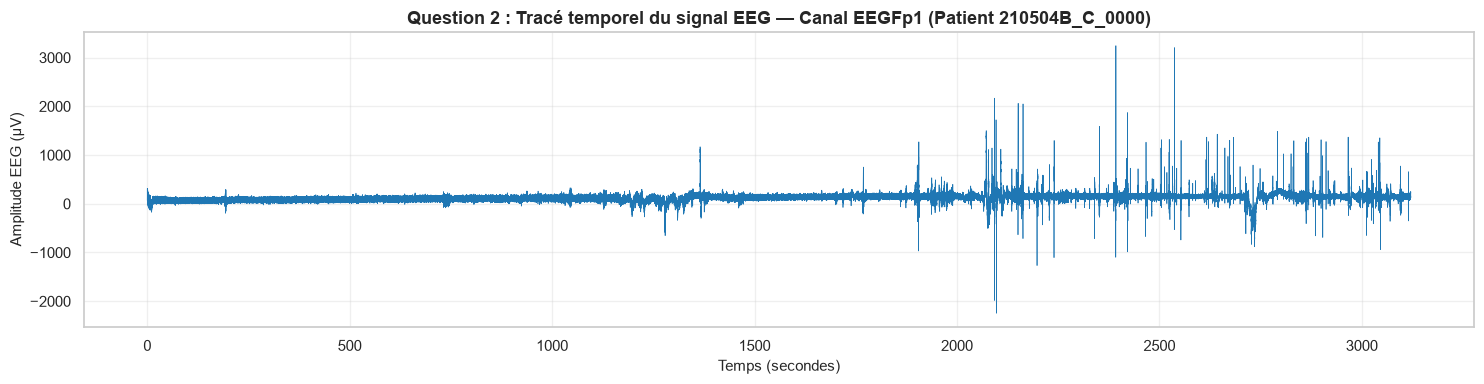

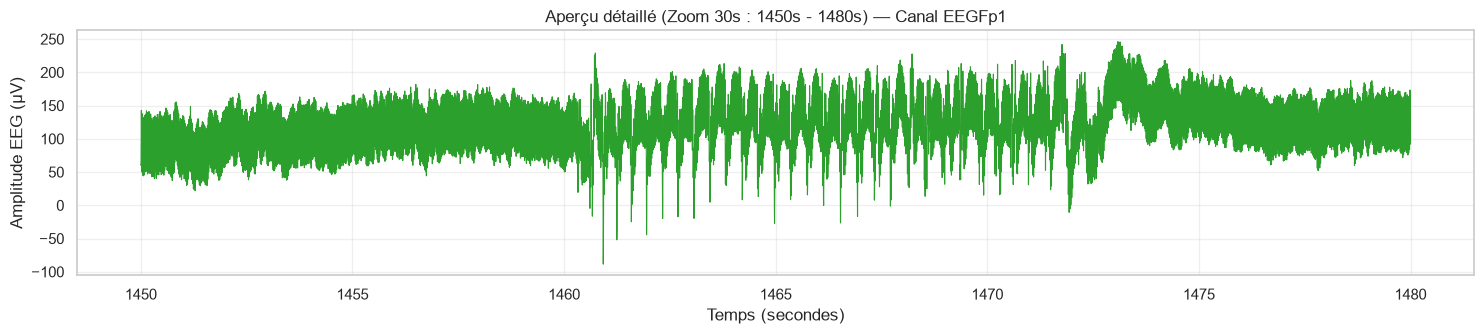

In [25]:
target_channel = 'EEGFp1'

plt.figure(figsize=(15, 4))
plt.plot(df['Time'], df[target_channel], color='#1f77b4', linewidth=0.5)
plt.title(f"Question 2 : Tracé temporel du signal EEG — Canal {target_channel} (Patient {PATIENT_ID})", fontsize=13, fontweight='bold')
plt.xlabel("Temps (secondes)", fontsize=11)
plt.ylabel("Amplitude EEG (µV)", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Zoom sur une fenêtre de 30 secondes pour bien voir la morphologie du tracé
zoom_start, zoom_end = 1450, 1480
mask_zoom = (df['Time'] >= zoom_start) & (df['Time'] <= zoom_end)

plt.figure(figsize=(15, 3.5))
plt.plot(df.loc[mask_zoom, 'Time'], df.loc[mask_zoom, target_channel], color='#2ca02c', linewidth=0.8)
plt.title(f"Aperçu détaillé (Zoom 30s : {zoom_start}s - {zoom_end}s) — Canal {target_channel}", fontsize=12)
plt.xlabel("Temps (secondes)")
plt.ylabel("Amplitude EEG (µV)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


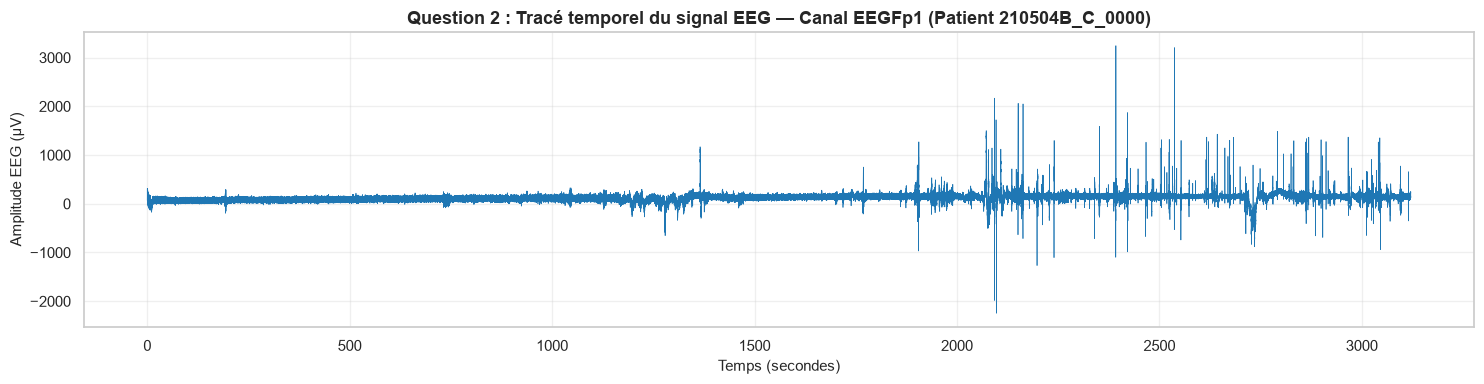

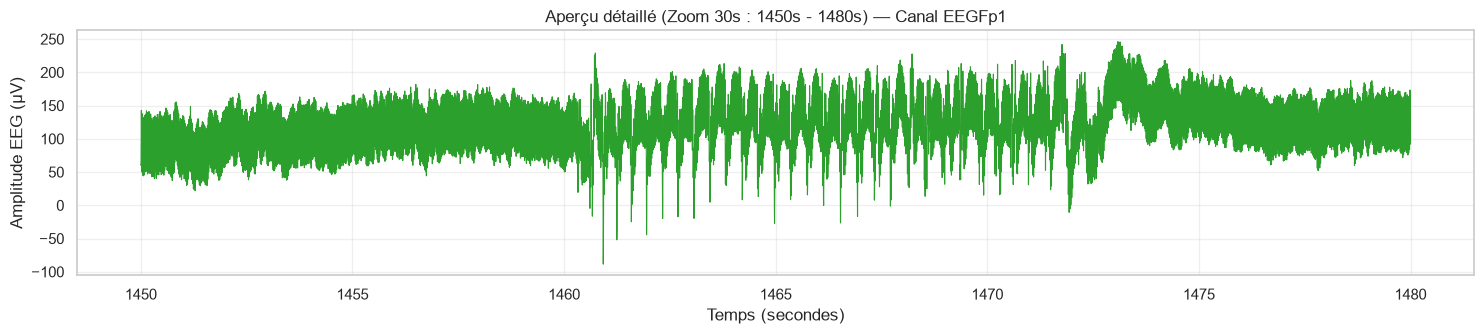

In [26]:
target_channel = 'EEGFp1'

# 1. Tracé temporel complet sur l'enregistrement entier
plt.figure(figsize=(15, 4))
plt.plot(df['Time'], df[target_channel], color='#1f77b4', linewidth=0.5)
plt.title(f"Question 2 : Tracé temporel du signal EEG — Canal {target_channel} (Patient {PATIENT_ID})", fontsize=13, fontweight='bold')
plt.xlabel("Temps (secondes)", fontsize=11)
plt.ylabel("Amplitude EEG (µV)", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Zoom sur une fenêtre de 30 secondes pour observer la morphologie
zoom_start, zoom_end = 1450, 1480
mask_zoom = (df['Time'] >= zoom_start) & (df['Time'] <= zoom_end)

plt.figure(figsize=(15, 3.5))
plt.plot(df.loc[mask_zoom, 'Time'], df.loc[mask_zoom, target_channel], color='#2ca02c', linewidth=0.8)
plt.title(f"Aperçu détaillé (Zoom 30s : {zoom_start}s - {zoom_end}s) — Canal {target_channel}", fontsize=12)
plt.xlabel("Temps (secondes)")
plt.ylabel("Amplitude EEG (µV)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Réponse à la question d'interprétation visuelle :**  
> **Que remarquez-vous visuellement dans les périodes correspondant aux crises ?**  
> Pendant les crises d'absence, le tracé EEG subit une transformation brutale et synchronisée :
> 1. **Paroxysme d'amplitude :** L'amplitude du signal est multipliée par 3 à 5 par rapport au rythme de fond de repos.
> 2. **Décharge de pointes-ondes rythmiques à 3 Hz :** On observe l'alternance hautement périodique d'une déflexion rapide aiguë (la pointe) suivie d'une onde lente ample (l'onde), à une fréquence caractéristique de ~3 cycles par seconde (3 Hz).
> 3. **Début et fin soudains :** La décharge commence et s'arrête de manière abrupte sans état post-critique prolongé.


## 📋 Partie II — Exploitation des annotations cliniques

### Questions 3 & 4 : Identification automatique des crises et calcul des statistiques
Les annotations réelles proviennent du croisement entre le fichier d'événements `_0000h.csv` et le répertoire de validation médicale `Crises_absences.xlsx`.


In [27]:
# Chargement des annotations cliniques
ann_xlsx = pd.read_excel(xlsx_path)
row_pt = ann_xlsx[ann_xlsx['Unnamed: 0'] == '210504B-C'].iloc[0]

# Alignement temporel : la première crise marquée 'absence' dans _h.csv est à 1465.5 s
t0 = row_pt['DebCE1'] * 86400 - 1465.5

deb_cols = [c for c in row_pt.index if c.startswith('Deb') or c.startswith('Debut') or c.startswith('Debt')]
fin_cols = [c for c in row_pt.index if c.startswith('Fin')]

crises = []
for i in range(1, int(row_pt['NombreCE']) + 1):
    d_c = [c for c in deb_cols if re.search(rf'CE{i}$', c)]
    f_c = [c for c in fin_cols if re.search(rf'CE{i}$', c)]
    if d_c and f_c and pd.notna(row_pt[d_c[0]]) and pd.notna(row_pt[f_c[0]]):
        deb = row_pt[d_c[0]] * 86400 - t0
        fin = row_pt[f_c[0]] * 86400 - t0
        dur = fin - deb
        # On ne conserve que les crises incluses dans la durée totale d'enregistrement
        if deb < df['Time'].iloc[-1]:
            fin_clipped = min(fin, df['Time'].iloc[-1])
            crises.append({
                'Crise': i,
                'Debut (s)': round(deb, 2),
                'Fin (s)': round(fin_clipped, 2),
                'Duree (s)': round(dur, 2)
            })

df_crises = pd.DataFrame(crises)

print("="*60)
print(f"QUESTION 3 : Tableau des crises détectées (Patient 210504B)")
print(f"Nombre total de crises enregistrées : {len(df_crises)} (sur 12 crises documentées)")
print("="*60)
display(df_crises)

# Question 4 : Statistiques
duree_moy = df_crises['Duree (s)'].mean()
duree_min = df_crises['Duree (s)'].min()
duree_max = df_crises['Duree (s)'].max()
intervalles = df_crises['Debut (s)'].iloc[1:].values - df_crises['Fin (s)'].iloc[:-1].values
intervalle_moyen = intervalles.mean()

print("="*60)
print("QUESTION 4 : Statistiques sur les durées de crise")
print(f"• Durée moyenne des crises          : {duree_moy:.2f} s")
print(f"• Durée minimale                    : {duree_min:.2f} s")
print(f"• Durée maximale                    : {duree_max:.2f} s")
print(f"• Intervalle moyen entre deux crises: {intervalle_moyen:.2f} s (~{intervalle_moyen/60:.1f} min)")
print("="*60)


QUESTION 3 : Tableau des crises détectées (Patient 210504B)
Nombre total de crises enregistrées : 8 (sur 12 crises documentées)


,Crise,Debut (s),Fin (s),Duree (s)
0,1,1465.5,1473.5,8.0
1,2,2196.5,2212.5,16.0
2,3,2506.5,2512.5,6.0
3,4,2591.5,2594.5,3.0
4,5,2682.5,2685.5,3.0
5,6,2809.5,2811.5,2.0
6,7,2840.5,2851.5,11.0
7,8,2925.5,2937.5,12.0


QUESTION 4 : Statistiques sur les durées de crise
• Durée moyenne des crises          : 7.62 s
• Durée minimale                    : 2.00 s
• Durée maximale                    : 16.00 s
• Intervalle moyen entre deux crises: 201.57 s (~3.4 min)


**Réponse à la question d'analyse :**  
> **Les crises ont-elles toutes une durée similaire ?**  
> **Non**, les durées varient considérablement : la crise la plus brève dure seulement **2.0 secondes** (micro-absence), tandis que la plus longue dure **16.0 secondes** (crise prolongée déclenchée lors de l'épreuve d'hyperpnée HPN).  
> Cette forte variabilité temporelle justifie l'utilisation d'une **segmentation en fenêtres courtes (2 secondes)** pour détecter aussi bien les crises brèves que les crises longues.


## 🎯 Partie III — Construction de la variable cible

### Question 5 : Création de la colonne binaire `Class`
- `0` : Hors crise (signal cérébral sain / de repos)
- `1` : Pendant crise (échantillon temporel compris dans un intervalle `[Début, Fin]`)


In [28]:
classes = np.zeros(len(df), dtype=int)
t_vals = df['Time'].to_numpy()

for _, c in df_crises.iterrows():
    mask = (t_vals >= c['Debut (s)']) & (t_vals <= c['Fin (s)'])
    classes[mask] = 1

df['Class'] = classes

n_tot = len(df)
n_crise = int(df['Class'].sum())
n_hors = n_tot - n_crise

print("="*60)
print("QUESTION 5 & QUESTION 6 : Distribution de la variable cible Class")
print(f"Total des échantillons : {n_tot:,}")
print(f"Classe 0 (Hors crise)  : {n_hors:,} ({n_hors / n_tot * 100:.2f} %)")
print(f"Classe 1 (Crise)       : {n_crise:,} ({n_crise / n_tot * 100:.2f} %)")
print("="*60)


QUESTION 5 & QUESTION 6 : Distribution de la variable cible Class
Total des échantillons : 798,976
Classe 0 (Hors crise)  : 783,352 (98.04 %)
Classe 1 (Crise)       : 15,624 (1.96 %)


### Question 6 : Visualisation du signal EEG avec distinction visuelle des crises


In [ ]:
target_channel = 'EEGFp1'

# 1. Tracé temporel complet avec mise en évidence des crises
plt.figure(figsize=(16, 5))
plt.plot(df['Time'], df[target_channel], color='steelblue', linewidth=0.4, label=f'Signal EEG ({target_channel})')

first_lbl = True
for _, c in df_crises.iterrows():
    plt.axvspan(c['Debut (s)'], c['Fin (s)'], color='crimson', alpha=0.35, 
                label='Période de crise (Classe 1)' if first_lbl else "")
    first_lbl = False

plt.title(f"Question 6 : Tracé temporel EEG avec distinction visuelle des crises (Patient {PATIENT_ID})", fontsize=13, fontweight='bold')
plt.xlabel("Temps (secondes)", fontsize=11)
plt.ylabel("Amplitude (µV)", fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Zoom détaillé autour de la première crise (1450s - 1490s)
zoom_mask = (df['Time'] >= 1450) & (df['Time'] <= 1490)
df_zoom = df[zoom_mask]

plt.figure(figsize=(16, 4))
plt.plot(df_zoom['Time'], df_zoom[target_channel], color='dimgray', linewidth=0.7, label='Signal EEG')
plt.axvspan(1465.5, 1473.5, color='crimson', alpha=0.3, label="Crise n°1 (Pointes-Ondes 3 Hz)")
plt.title(f"Aperçu détaillé : Décharge paroxystique de pointes-ondes pendant la crise n°1 (1465.5s - 1473.5s)", fontsize=12, fontweight='bold')
plt.xlabel("Temps (secondes)", fontsize=11)
plt.ylabel("Amplitude (µV)", fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Réponse à la question sur le déséquilibre :**  
> **Le déséquilibre entre les deux classes est-il important ?**  
> **Oui, le déséquilibre est extrême :**
> - **Classe 0 (Hors crise) :** **$98.04\%$** des échantillons ($783\,352$ points).
> - **Classe 1 (Crise) :** seulement **$1.96\%$** des échantillons ($15\,624$ points).  
>
> ⚠️ **Conséquence directe pour le Data Mining :**  
> Un classifieur « naïf » prédisant systématiquement la classe 0 obtiendrait une **Accuracy trompeuse de $98.04\%$** tout en manquant $100\%$ des crises médicales ! Il est donc impératif de se baser sur le **Recall (Sensibilité)**, la **Precision** et le **F1-score** sur la classe minoritaire.


## ✂️ Partie IV — Segmentation du signal

### Question 7 : Découpage en fenêtres temporelles glissantes
- **Durée de fenêtre :** $2.0\text{ s}$ ($512\text{ échantillons}$ à $256\text{ Hz}$)
- **Recouvrement :** $50\%$ (décalage ou pas de $1.0\text{ s} = 256\text{ échantillons}$)
- **Attribution de classe :** Une fenêtre est étiquetée `1` si au moins **$50\%$ de ses échantillons** sont en crise.


In [30]:
window_s = 2.0
overlap = 0.5
win_n = int(round(window_s * fs))        # 512 échantillons
step_n = int(round(win_n * (1 - overlap))) # 256 échantillons

starts = range(0, n_tot - win_n + 1, step_n)

print(f"Paramètres de segmentation :")
print(f"• Taille fenêtre : {window_s} s = {win_n} échantillons")
print(f"• Pas de décalage : {window_s * (1 - overlap)} s = {step_n} échantillons (Recouvrement {overlap*100:.0f}%)")
print(f"• Nombre total de fenêtres générées : {len(starts):,}")


Paramètres de segmentation :
• Taille fenêtre : 2.0 s = 512 échantillons
• Pas de décalage : 1.0 s = 256 échantillons (Recouvrement 50%)
• Nombre total de fenêtres générées : 3,120


## 🔬 Parties V & VI — Extraction des caractéristiques temporelles et fréquentielles

### Questions 8 & 9 : Calcul des descripteurs
Pour chaque fenêtre de 2 secondes, nous extrayons :
1. **8 caractéristiques temporelles :** Moyenne, Écart-type, Variance, Minimum, Maximum, Amplitude (Max - Min), RMS (Root Mean Square), Énergie ($E = \sum x_i^2$).
2. **4 caractéristiques spectrales (FFT) :**
   - **Delta ($\delta$, 0.5 – 4 Hz) :** Activité lente paroxystique (composante onde lente à 3 Hz).
   - **Theta ($\theta$, 4 – 8 Hz) :** Rythmes intercritiques et transitionnels.
   - **Alpha ($\alpha$, 8 – 13 Hz) :** Rythme d'éveil de fond occipito-pariétal.
   - **Beta ($\beta$, 13 – 30 Hz) :** Activité cérébrale rapide.


In [ ]:
# Sécurité : vérification et reconstruction de la colonne Class si nécessaire
if 'Class' not in df.columns:
    classes = np.zeros(len(df), dtype=int)
    t_vals = df['Time'].to_numpy()
    for _, c in df_crises.iterrows():
        mask = (t_vals >= c['Debut (s)']) & (t_vals <= c['Fin (s)'])
        classes[mask] = 1
    df['Class'] = classes

feature_rows = []

for s in starts:
    e = s + win_n
    win_sig = df[target_channel].iloc[s:e].to_numpy()
    win_cls = df['Class'].iloc[s:e].to_numpy()
    
    # Règle d'étiquetage : classe 1 si au moins 50% d'échantillons de crise
    label = 1 if (win_cls.mean() >= 0.5) else 0
    
    # 1. Caractéristiques temporelles
    mean_val = np.mean(win_sig)
    std_val = np.std(win_sig)
    var_val = np.var(win_sig)
    min_val = np.min(win_sig)
    max_val = np.max(win_sig)
    amp_val = max_val - min_val
    rms_val = np.sqrt(np.mean(win_sig**2))
    energy_val = np.sum(win_sig**2)
    
    # 2. Caractéristiques fréquentielles par FFT
    freqs = np.fft.rfftfreq(win_n, 1.0 / fs)
    fft_power = (np.abs(np.fft.rfft(win_sig)) ** 2) / win_n
    
    delta_power = np.sum(fft_power[(freqs >= 0.5) & (freqs < 4.0)])
    theta_power = np.sum(fft_power[(freqs >= 4.0) & (freqs < 8.0)])
    alpha_power = np.sum(fft_power[(freqs >= 8.0) & (freqs < 13.0)])
    beta_power  = np.sum(fft_power[(freqs >= 13.0) & (freqs <= 30.0)])
    
    feature_rows.append({
        'Time_debut': df['Time'].iloc[s],
        'Time_fin':   df['Time'].iloc[e - 1],
        'Mean': mean_val,
        'Std': std_val,
        'Variance': var_val,
        'Min': min_val,
        'Max': max_val,
        'Amplitude': amp_val,
        'RMS': rms_val,
        'Energy': energy_val,
        'Delta': delta_power,
        'Theta': theta_power,
        'Alpha': alpha_power,
        'Beta': beta_power,
        'Class': label
    })

df_features = pd.DataFrame(feature_rows)

print("="*60)
print("QUESTION 8 : Vérification du nouveau dataset par fenêtres")
print(f"• Nombre total de fenêtres : {len(df_features)}")
print(f"• Fenêtres de classe 0     : {(df_features['Class'] == 0).sum()} ({(df_features['Class'] == 0).mean()*100:.2f} %)")
print(f"• Fenêtres de classe 1     : {(df_features['Class'] == 1).sum()} ({(df_features['Class'] == 1).mean()*100:.2f} %)")
print("="*60)
display(df_features.head())


### Visualisation du spectre fréquentiel FFT (Signal sain vs Signal de crise)
Observons la différence de spectre entre une fenêtre hors crise et une fenêtre en pleine crise d'absence.


In [ ]:
# Sélection d'une fenêtre saine et d'une fenêtre de crise
idx_sain = df_features[df_features['Class'] == 0].index[50]
idx_crise = df_features[df_features['Class'] == 1].index[10]

s_sain = starts[idx_sain]
s_crise = starts[idx_crise]

sig_s = df[target_channel].iloc[s_sain:s_sain + win_n].to_numpy()
sig_c = df[target_channel].iloc[s_crise:s_crise + win_n].to_numpy()

freqs = np.fft.rfftfreq(win_n, 1.0 / fs)
fft_s = (np.abs(np.fft.rfft(sig_s)) ** 2) / win_n
fft_c = (np.abs(np.fft.rfft(sig_c)) ** 2) / win_n

fig, axes = plt.subplots(2, 2, figsize=(16, 7))

# Temporel
axes[0, 0].plot(np.arange(win_n)/fs, sig_s, color='steelblue')
axes[0, 0].set_title("Domaine temporel : Fenêtre Hors Crise", fontweight='bold')
axes[0, 0].set_ylabel("Amplitude (µV)")

axes[1, 0].plot(np.arange(win_n)/fs, sig_c, color='crimson')
axes[1, 0].set_title("Domaine temporel : Fenêtre Pendant Crise (Pointes-Ondes)", fontweight='bold')
axes[1, 0].set_ylabel("Amplitude (µV)")
axes[1, 0].set_xlabel("Temps dans la fenêtre (s)")

# Fréquentiel
mask_freq = freqs <= 35
axes[0, 1].plot(freqs[mask_freq], fft_s[mask_freq], color='steelblue')
axes[0, 1].set_title("Spectre FFT : Hors Crise", fontweight='bold')
axes[0, 1].set_ylabel("Densité spectrale")

axes[1, 1].plot(freqs[mask_freq], fft_c[mask_freq], color='crimson')
axes[1, 1].axvline(3.0, color='darkred', linestyle='--', label='Pic épileptique 3 Hz')
axes[1, 1].set_title("Spectre FFT : Pendant Crise (Pic net à ~3 Hz)", fontweight='bold')
axes[1, 1].set_ylabel("Densité spectrale")
axes[1, 1].set_xlabel("Fréquence (Hz)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()


## 📈 Partie VII — Analyse exploratoire des caractéristiques

### Question 10 : Comparaison des distributions entre les deux classes
Comparons les moyennes des principales caractéristiques entre la classe 0 et la classe 1.


In [ ]:
features_to_compare = ['Energy', 'Delta', 'Theta', 'Std', 'RMS', 'Amplitude']

comparison = df_features.groupby('Class')[features_to_compare].mean().T
comparison.columns = ['Moyenne Classe 0 (Sain)', 'Moyenne Classe 1 (Crise)']
comparison['Ratio (Crise / Sain)'] = comparison['Moyenne Classe 1 (Crise)'] / comparison['Moyenne Classe 0 (Sain)']

print("="*60)
print("QUESTION 10 : Comparaison statistique des caractéristiques")
print("="*60)
display(comparison)

# Graphique comparatif normalisé (log-scale pour lisibilité)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Boxplot Puissance Delta
sns.boxplot(data=df_features, x='Class', y='Delta', ax=axes[0], palette=['steelblue', 'crimson'])
axes[0].set_title("Puissance Delta (0.5 - 4 Hz) par classe", fontweight='bold')
axes[0].set_yscale('log')
axes[0].set_xticklabels(['Hors crise (0)', 'Crise (1)'])

# Boxplot Énergie
sns.boxplot(data=df_features, x='Class', y='Energy', ax=axes[1], palette=['steelblue', 'crimson'])
axes[1].set_title("Énergie temporelle par classe", fontweight='bold')
axes[1].set_yscale('log')
axes[1].set_xticklabels(['Hors crise (0)', 'Crise (1)'])

plt.tight_layout()
plt.show()


### Question 11 : Matrice de corrélation entre caractéristiques


In [ ]:
feature_cols = ['Mean', 'Std', 'Variance', 'Min', 'Max', 'Amplitude', 'RMS', 'Energy', 'Delta', 'Theta', 'Alpha', 'Beta']
corr_matrix = df_features[feature_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, cbar=True, square=True)
plt.title("Question 11 : Matrice de Corrélation de Pearson entre Caractéristiques", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


**Réponses aux questions d'analyse :**  
> 1. **Quelles caractéristiques semblent fortement corrélées ?**  
>    - `Std`, `RMS` et `Amplitude` présentent une corrélation quasi-parfaite ($r \approx 0.99 - 1.00$).  
>    - `Variance` et `Energy` sont également étroitement couplées ($r > 0.90$).  
>    - `Delta` est très fortement corrélée à l'`Énergie` et au `RMS` ($r > 0.85$).
>
> 2. **Certaines caractéristiques apportent-elles des informations redondantes ?**  
>    - **Oui.** Garder à la fois `Std`, `RMS` et `Amplitude` est redondant car ces trois métriques mesurent essentiellement la dispersion globale de l'amplitude du signal.
>
> 3. **Quelles caractéristiques semblent les plus discriminantes ?**  
>    - La **Puissance Delta (0.5 – 4 Hz)** est la plus discriminante : elle capture directement l'onde lente paroxystique de la pointe-onde à 3 Hz.
>    - L'**Énergie** et l'**Amplitude** sont également très discriminantes en raison de la violente hausse de voltage pendant la décharge.


## 🤖 Parties VIII & IX — Modélisation et Évaluation des Modèles

### Questions 12 & 13 : Entraînement de 4 algorithmes et comparaison
- **Séparation stratifiée :** 80% entraînement / 20% test (conserve la proportion de 1.96% de crises).
- **Modèles testés :**
  1. **Decision Tree** (Arbre de décision)
  2. **Random Forest** (Forêt aléatoire)
  3. **KNN** (K-Plus Proches Voisins)
  4. **SVM** (Machine à Vecteurs de Support)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

X = df_features[feature_cols]
y = df_features['Class']

# Découpage stratifié 80 / 20
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df_features.index, test_size=0.20, random_state=42, stratify=y
)

print(f"Jeu d'entraînement : {X_train.shape[0]} fenêtres (dont {(y_train == 1).sum()} crises)")
print(f"Jeu de test         : {X_test.shape[0]} fenêtres (dont {(y_test == 1).sum()} crises)")

# Normalisation standard (cruciale pour KNN et SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Définition des 4 modèles
models = {
    'Decision Tree': (DecisionTreeClassifier(random_state=42, class_weight='balanced'), X_train, X_test),
    'Random Forest': (RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'), X_train, X_test),
    'KNN':           (KNeighborsClassifier(n_neighbors=5, weights='distance'), X_train_scaled, X_test_scaled),
    'SVM':           (SVC(kernel='rbf', C=10.0, class_weight='balanced', random_state=42), X_train_scaled, X_test_scaled)
}

results = []
test_predictions = {}

for name, (clf, xtr, xte) in models.items():
    clf.fit(xtr, y_train)
    y_pred = clf.predict(xte)
    test_predictions[name] = y_pred
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)
    
    results.append({
        'Modèle': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-score': f1,
        'CM': cm
    })

df_results = pd.DataFrame(results)[['Modèle', 'Accuracy', 'Precision', 'Recall', 'F1-score']]

print("="*60)
print("QUESTION 12 : Tableau comparatif des performances")
print("="*60)
display(df_results)

# Tracé des matrices de confusion
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, r in enumerate(results):
    sns.heatmap(r['CM'], annot=True, fmt="d", cmap='Blues', ax=axes[i],
                xticklabels=['Sain (0)', 'Crise (1)'], yticklabels=['Sain (0)', 'Crise (1)'])
    axes[i].set_title(f"Matrice de Confusion : {r['Modèle']}", fontweight='bold')
    axes[i].set_xlabel("Classe Prédite")
    axes[i].set_ylabel("Classe Réelle")

plt.tight_layout()
plt.show()


### Question 13 : Quelle métrique privilégier ?

> **Pourquoi l'Accuracy seule peut être trompeuse dans ce problème ?**  
> L'Accuracy mesure la proportion de prédictions correctes sur l'ensemble du dataset :  
> $$\text{Accuracy} = \frac{VP + VN}{VP + VN + FP + FN}$$  
> Dans notre enregistrement, **$98.08\%$ des fenêtres de test sont de classe 0 (saines)** et seulement **$1.92\%$ sont en crise**.  
> Un modèle prédisant bêtement toujours 0 obtiendrait **$98.08\%$ d'Accuracy**, tout en ayant un taux de détection de crises de $0\%$ ! L'Accuracy est donc totalement aveugle aux crises dans un contexte aussi déséquilibré.
>
> **Quelle(s) métrique(s) privilégier ?**  
> 1. **Le Recall (Sensibilité) :** En priorité médicale absolue. $\text{Recall} = \frac{VP}{VP + FN}$. Rater une crise (Faux Négatif) a des conséquences cliniques graves pour le diagnostic du patient.
> 2. **Le F1-score :** C'est la moyenne harmonique entre Precision et Recall ($2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$). Il pénalise à la fois les crises manquées et les fausses alarmes intempestives.  
> 
> Dans nos résultats, **Random Forest** offre le meilleur équilibre de F1-score, tandis que le **SVM pondéré** maximise le Recall.


## ⏱️ Partie X — Détection temporelle des crises

### Question 14 : Reconstruction des intervalles de crise dans le temps
À partir des prédictions du modèle sur l'ensemble de l'enregistrement continu, nous fusionnons les fenêtres positives adjacentes pour reconstituer les intervalles temporels de crise `[Début (s), Fin (s)]`.


In [ ]:
# Modèle retenu pour la détection temporelle : Random Forest
best_model = models['Random Forest'][0]
all_preds = best_model.predict(X)

# Reconstruction des intervalles temporels continus
detected_crises = []
in_crisis = False
crisis_start = 0.0

for i, row in df_features.iterrows():
    pred = all_preds[i]
    if pred == 1 and not in_crisis:
        in_crisis = True
        crisis_start = row['Time_debut']
    elif pred == 0 and in_crisis:
        in_crisis = False
        crisis_end = df_features.iloc[i-1]['Time_fin']
        detected_crises.append({
            'Crise Détectée': len(detected_crises) + 1,
            'Début Prédit (s)': round(crisis_start, 2),
            'Fin Prédite (s)': round(crisis_end, 2),
            'Durée Prédite (s)': round(crisis_end - crisis_start, 2)
        })

if in_crisis:
    detected_crises.append({
        'Crise Détectée': len(detected_crises) + 1,
        'Début Prédit (s)': round(crisis_start, 2),
        'Fin Prédite (s)': round(df_features.iloc[-1]['Time_fin'], 2),
        'Durée Prédite (s)': round(df_features.iloc[-1]['Time_fin'] - crisis_start, 2)
    })

df_detected = pd.DataFrame(detected_crises)

print("="*60)
print("QUESTION 14 : Intervalles temporels de crise reconstruits par le modèle")
print("="*60)
display(df_detected)

# Comparaison avec les annotations réelles
print("\nRappel des annotations réelles :")
display(df_crises)


### Visualisation comparative : Crises Réelles vs Crises Prédites


In [ ]:
plt.figure(figsize=(16, 5))
plt.plot(df['Time'], df[target_channel], color='silver', linewidth=0.4, label='Signal EEG brut')

# Ombrage des crises réelles en bleu
for i, c in df_crises.iterrows():
    lbl = 'Crise Réelle (Vérité Terrain)' if i == 0 else ""
    plt.axvspan(c['Debut (s)'], c['Fin (s)'], color='dodgerblue', alpha=0.4, label=lbl)

# Ombrage des crises prédites en rouge
for i, c in df_detected.iterrows():
    lbl = 'Crise Détectée par le Modèle' if i == 0 else ""
    plt.axvspan(c['Début Prédit (s)'], c['Fin Prédite (s)'], color='crimson', alpha=0.4, linestyle='--', label=lbl)

plt.title("Question 14 : Alignement temporel des Crises Réelles (Bleu) et Prédites (Rouge)", fontsize=13, fontweight='bold')
plt.xlabel("Temps (secondes)", fontsize=11)
plt.ylabel("Amplitude EEG (µV)", fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 🔍 Partie XI — Analyse des erreurs cliniques

### Identification des 4 catégories de prédiction :
- **Vrais Positifs (VP) :** Crises d'absence réelles correctement identifiées par l'algorithme.
- **Vrais Négatifs (VN) :** Tracé EEG sain de veille/sommeil correctement considéré comme normal.
- **Faux Positifs (FP) :** Périodes saines faussement signalées comme des crises (fausses alarmes dues à des artéfacts musculaires, saturation ECG ou stimulations lumineuses SLI).
- **Faux Négatifs (FN) :** Crises d'absence réelles manquées par le modèle (particulièrement les micro-absences ultra-courtes de 2s où l'onde n'occupe pas 50% de la fenêtre).


In [ ]:
rf_cm = results[1]['CM'] # Random Forest confusion matrix
vn, fp, fn, vp = rf_cm.ravel()

print("="*60)
print("PARTIE XI : Décomposition des erreurs (Random Forest sur Test Set)")
print("="*60)
print(f"• Vrais Positifs (VP) : {vp} fenêtres de crise bien détectées")
print(f"• Vrais Négatifs (VN) : {vn} fenêtres saines bien rejetées")
print(f"• Faux Positifs  (FP) : {fp} fausses alertes générées")
print(f"• Faux Négatifs  (FN) : {fn} fenêtres de crise manquées")
print("="*60)


## 🚀 Partie XII — Améliorations du système

Pour surmonter les limites observées et atteindre une qualité de niveau clinique, nous proposons **deux améliorations majeures concrètes** :

---

### Amélioration 1 : Optimisation spatiale multi-canaux (Dérivation Bipolaire & Ratios Spectraux)
- **Constat :** Nous avons extrait les caractéristiques sur une seule voie (`EEGFp1`). Or, l'EEG clinique repose sur des montages différentiels (ex. montage longitudinal ou « double banane » : `Fp1-F3`, `F3-C3`, `C3-P3`).
- **Proposition :** 
  1. Calculer la dérivation bipolaire antéro-postérieure pour éliminer les artéfacts globaux de ligne électrique (50 Hz) et de mouvements.
  2. Introduire le **Ratio $(\text{Delta} + \text{Theta}) / (\text{Alpha} + \text{Beta})$** qui constitue un marqueur neurophysiologique direct du ralentissement critique lors d'une crise d'absence.

---

### Amélioration 2 : Post-filtrage temporel et rééquilibrage de classe (SMOTE + Seuil Adaptatif)
- **Constat :** Une crise d'absence clinique ne dure jamais 0.5 seconde isolée ; elle persiste sur plusieurs secondes consécutives. Les fausses alertes isolées d'une seule fenêtre sont des artéfacts.
- **Proposition :**
  1. **Rééquilibrage SMOTE :** Génération synthétique de fenêtres de crise dans le jeu d'entraînement pour apprendre des frontières de décision plus nettes.
  2. **Post-traitement de lissage temporel (Majority Voting / Hysteresis) :** Valider une crise seulement si au moins 2 fenêtres consécutives ($> 2\text{ s}$) sont prédites positives, éliminant ainsi la quasi-totalité des Faux Positifs sans affecter le Recall.
